# Content
1. Dataset description
2. Hypothesis
3. Goal
4. Objectives
5. Data preparation
6. Machine learning algorithm
7. 1st NN
8. 2nd NN
9. Comparison of the best models
10. Conclusions

# Dataset description

**Source:** Lithuanian Open Data Portal (data.gov.lt), dataset *"Priėmimo į aukštojo mokslo įstaigas prašymų duomenys"* (Higher education admission applications), published by **LAMA BPO**

- API: `https://get.data.gov.lt/datasets/gov/lamabpo/aukstosios_mokyklos/:ns`
- Structure description: [atviriduomenys/manifest – aukstuju_prasymai.csv](https://github.com/atviriduomenys/manifest/blob/master/datasets/gov/lamabpo/aukstuju_prasymai.csv)
- Period: admission years **2024 and 2025**
- Data is real, anonymised (person and programme IDs are hashed) and not cleaned.

The dataset consists of 3 related tables:

| Table | Rows | One row is | Key |
|---|---|---|---|
| `Prasymas` (applications) | 285 926 | one study programme chosen by an applicant in one admission round | `asmens_id`, `programos_id` |
| `Profilis` (applicant profiles) | 56 074 | one applicant | `asmens_id` |
| `Programa` (study programmes) | 3 187 | one study programme in one year | `programos_id` |

**`Prasymas` – applications**

| Column | Description |
|---|---|
| `prasymo_id`, `asmens_id`, `programos_id` | application, applicant and programme IDs |
| `pasirinkimo_data` | date and time the programme was chosen |
| `priemimo_etapas`, `etapo_pradzia`, `etapo_pabaiga` | admission round (main / additional) and its start and end dates |
| `prioriteto_nr` | priority of the programme in the applicant's list |
| `finansavimas` | funding type: `VF` – state-funded, `VNF` – self-paid |
| `ar_dalyvavo_konkurse` | whether the student took part in VF competition |
| `ar_pakviete` | whether the applicant was invited to study |
| `pakvietimo_data` | date of the invitation |
| **`ar_pasirase`** | **whether the invited applicant signed the study contract (target)** |

**`Profilis` – applicant profiles**

| Column | Description |
|---|---|
| `gimimo_metai` | year of birth (stored as a date, e.g. `2005-01-01`) |
| `lytis` | gender |
| `ar_galimai_uzsienietis` | possibly a foreigner (no Lithuanian school data) |
| `issilavinimo_institucija`, `issilavinim_inst_jar` | school where the diploma was obtained |
| `issilavinimo_sav`, `issilavinimo_sav_kodas` | municipality of the school |
| `asm_gyv_sav`, `asm_gyv_tipas` | municipality of residence and its type (city / rural) |

**`Programa` – study programmes**

| Column | Description |
|---|---|
| `programos_valst_kodas`, `programos_pavadinimas` | programme state code and name |
| `mokymo_istaiga`, `istaigos_jar` | higher education institution |
| `apskritis`, `savivaldybe` | county and municipality where the programme is taught |
| `programos_metai` | admission year |

**Target subset:** 47 826 applications received an invitation (`ar_pakviete = true`); of them 39 205 (≈ 82 %) signed a contract and 8 621 (≈ 18 %) did not – the classes are imbalanced.

**Data quality problems that I will probably have to deal with during data cleaning:**
- the data is split into 3 tables that need to be joined.
- missing values (e.g. `pakvietimo_data` is empty for not invited applicants, school and municipality are missing for foreigners).
- dates stored in different formats.
- inconsistent text values (school and municipality names, e.g. *"Vilniaus m. sav."* vs *"Vilniaus miesto savivaldybė"*)
- the same applicant appears in several rows and rounds
- columns that leak the target (e.g. `pakvietimo_data`) must be excluded
- class imbalance.

# Hypothesis

Whether an invited applicant signs the study contract can be predicted from information available at the moment of the invitation, without exam scores.

1. Applicants invited to a **higher-priority** choice (priority 1–2) and to a **state-funded (VF)** place sign the contract more often than those invited to a low-priority or self-paid place.
2. Applicants invited in the **main admission round** and to a programme in the **same municipality / county where they live** sign the contract more often.
3. A gradient boosting model (**XGBoost**) and neural networks trained on these features will perform **better than the majority-class baseline** (always predicting "signed", around 82 % accuracy), measured by ROC AUC and F1 score of the minority class ("did not sign").

# Goal

To build and compare machine learning models (XGBoost and two neural networks) that predict whether an applicant invited to a Lithuanian higher education programme will sign the study contract (`ar_pasirase`), and to identify which application and applicant characteristics influence this decision the most.

# Objectives

1. Download the three tables (`Prasymas`, `Profilis`, `Programa`) from the data.gov.lt API and join them into one dataset.
2. Prepare the dataset: keep only invited applications, remove duplicates and leaking columns, fix missing values, data types and inconsistent text values.
3. Create new features (e.g. applicant age, "studies in home municipality / county", days between programme choice and round end, number of choices made by the applicant).
4. Perform exploratory data analysis: histograms, bar charts of the sign rate by priority, funding type and region, correlation coefficients.
5. Encode categorical features, scale numeric features, split data into training and test sets, handle class imbalance.
6. Train an XGBoost classifier and analyse the influence of its parameters (number of trees, depth, learning rate, `scale_pos_weight`).
7. Train the 1st neural network – multilayer perceptron (MLP) – and analyse its parameters (layers, neurons, activation, optimizer, dropout).
8. Train the 2nd neural network – MLP with embedding layers for high-cardinality categories (programme, institution, municipality) – and analyse its parameters.
9. Evaluate all models on training and test sets (accuracy, precision, recall, F1, ROC AUC, confusion matrix) and compare the best models.
10. Draw conclusions and check whether the hypothesis is confirmed.

# Data preparation

In [3]:
# your code

## Libraries

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data loading

In [5]:
DATA_DIR = Path("data")

prasymas_raw = pd.read_csv(DATA_DIR / "Prasymas.csv", dtype=str)
profilis_raw = pd.read_csv(DATA_DIR / "Profilis.csv", dtype=str)
programa_raw = pd.read_csv(DATA_DIR / "Programa.csv", dtype=str)
raw_tables = {"Prasymas": prasymas_raw, "Profilis": profilis_raw, "Programa": programa_raw}

for name, t in raw_tables.items():
    print(f"{name:9s} {t.shape[0]:>8,} rows x {t.shape[1]} columns")

Prasymas   285,926 rows x 17 columns
Profilis    56,074 rows x 14 columns
Programa     3,187 rows x 15 columns


In [6]:
for name, t in raw_tables.items():
    print(name)
    display(t.head(3))

Prasymas


,_type,_id,_revision,_page.next,prasymo_id,asmens_id,pasirinkimo_data,priemimo_etapas,etapo_pradzia,etapo_pabaiga,prioriteto_nr,programos_id,finansavimas,ar_dalyvavo_konkurse,ar_pakviete,pakvietimo_data,ar_pasirase
0,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,891df7a8-b317-42b7-b06d-07d969889006,0dafab19-dce5-4547-a128-a8b0e85a2174,NaN,0000052b9b83e61,2c3167f5650cada,2024-08-08T11:50:53,Papildomo priėmimo pirmasis etapas,2024-08-05,2024-08-14,2,6b39500e2bad880,VF,True,False,NaN,False
1,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,d6093ed0-729c-487f-b83f-87a8af633284,63b327f5-13d1-4693-bb4f-e8672785e30a,NaN,000007be399668e,20e838045ee8c70,2025-08-16T17:00:40,Papildomas priėmimas,2025-08-15,2025-08-23,1,fe84c02be32ae53,VNF,True,True,2025-08-21,False
2,datasets/gov/lamabpo/aukstosios_mokyklos/Prasymas,a3c43940-e806-4581-bdd5-ce1a5933d7bb,e996a51c-dda7-48b7-ac5a-a1ce86c6423a,NaN,00005a09461640f,9dab57a9db04677,2025-07-16T01:23:18,Pagrindinis priėmimas,2025-06-01,2025-08-14,1,d68f9111561b520,VF,True,True,2025-08-10,True


Profilis


,_type,_id,_revision,_page.next,asmens_id,ar_galimai_uzsienietis,gimimo_metai,lytis,issilavinim_inst_jar,issilavinimo_institucija,issilavinimo_sav_kodas,issilavinimo_sav,asm_gyv_sav,asm_gyv_tipas
0,datasets/gov/lamabpo/aukstosios_mokyklos/Profilis,b1b69046-f44c-4d3a-975c-ab1b275fac6a,3559910d-0b27-4302-84eb-9d48ccea6ec4,NaN,0000ce94c572e99,False,2005-01-01,vyras,190006438,Vilniaus Pilaitės gimnazija,13,Vilniaus m. sav.,Vilniaus m. sav.,miestas
1,datasets/gov/lamabpo/aukstosios_mokyklos/Profilis,dd928255-ccae-476a-b94e-eb92c541e74b,0b6f7e61-e4ff-4a69-a93d-9ec22e17b8dd,NaN,0001a49787408bc,False,2005-01-01,moteris,300594538,Panevėžio Vytauto Mikalausko menų gimnazija,27,Panevėžio m. sav.,Panevėžio m. sav.,miestas
2,datasets/gov/lamabpo/aukstosios_mokyklos/Profilis,1721d316-9c5f-4f2d-b816-5025e9aa4871,441a6d6c-189e-496f-bdd5-acce3b0308b0,NaN,00025df8f3baf8a,False,2005-01-01,vyras,190553261,Telšių Žemaitės gimnazija,78,Telšių r. sav.,Palangos m. sav.,miestas


Programa


,_type,_id,_revision,_page.next,programos_id,programos_metai,programos_valst_kodas,programos_pavadinimas,istaigos_jar,jar_validacija,mokymo_istaiga,apskrities_kodas,apskritis,savivaldybes_kodas,savivaldybe
0,datasets/gov/lamabpo/aukstosios_mokyklos/Programa,bf0eb412-e941-4a67-8066-d2c5015850dc,8c7c4335-9751-49b4-9e81-b8b66f5f5a72,NaN,0007975e18105ad,2024-01-01,6121CX014,Gamtinė geografija ir okeanografija,211951150,Tinkamas,Klaipėdos universitetas,3,Klaipėdos apskritis,21,Klaipėdos miesto savivaldybė
1,datasets/gov/lamabpo/aukstosios_mokyklos/Programa,fd271cda-70a0-48cf-9b91-dea8cb9e9c19,24de61da-ed44-4ea6-877e-d06bed3c9882,NaN,002732e51d64a19,2025-01-01,6531LX134,Gyvenimo kokybės vadyba,291823650,Tinkamas,Viešoji įstaiga SMK Aukštoji mokykla,2,Kauno apskritis,19,Kauno miesto savivaldybė
2,datasets/gov/lamabpo/aukstosios_mokyklos/Programa,a4156210-eb1d-4cad-8d24-0ecff308d570,47a58a1c-82f2-4612-9c3e-fda3524489ec,NaN,002d4d3096a8cda,2025-01-01,6531GX040,Bendrosios praktikos slauga,111965284,Tinkamas,Kauno kolegija,1,Alytaus apskritis,11,Alytaus miesto savivaldybė


## Missing values

In [7]:
rows = []
for name, t in raw_tables.items():
    for col, n in t.isna().sum().items():
        if n > 0:
            rows.append({"table": name, "column": col, "missing": n, "missing %": round(100 * n / len(t), 1)})
pd.DataFrame(rows)

,table,column,missing,missing %
0,Prasymas,_page.next,285925,100.0
1,Prasymas,pakvietimo_data,238100,83.3
2,Profilis,_page.next,56073,100.0
3,Profilis,issilavinim_inst_jar,7395,13.2
4,Profilis,issilavinimo_institucija,7395,13.2
5,Profilis,issilavinimo_sav_kodas,7395,13.2
6,Profilis,issilavinimo_sav,7395,13.2
7,Profilis,asm_gyv_sav,3099,5.5
8,Profilis,asm_gyv_tipas,3096,5.5
9,Programa,_page.next,3186,100.0


In [8]:
foreign = profilis_raw["ar_galimai_uzsienietis"] == "True"
print("Possible foreigners:", foreign.sum())

print("Lithuanian applicants without school data:", profilis_raw.loc[~foreign, "issilavinimo_institucija"].isna().sum())
print("Lithuanian applicants without residence data:", profilis_raw.loc[~foreign, "asm_gyv_sav"].isna().sum())

Possible foreigners: 217
Lithuanian applicants without school data: 7178
Lithuanian applicants without residence data: 2882


## Municipality name fix

In [9]:
TECH_COLS = ["_type", "_id", "_revision", "_page.next"]          # API metadata, not data
BOOL_MAP = {"True": True, "False": False}

prasymas = prasymas_raw.drop(columns=TECH_COLS).copy()
for col in ["ar_pakviete", "ar_pasirase"]:
    prasymas[col] = prasymas[col].map(BOOL_MAP)
prasymas["prioriteto_nr"] = prasymas["prioriteto_nr"].astype(int)
prasymas["pasirinkimo_data"] = pd.to_datetime(prasymas["pasirinkimo_data"], format="%Y-%m-%dT%H:%M:%S")
for col in ["etapo_pradzia", "etapo_pabaiga"]:
    prasymas[col] = pd.to_datetime(prasymas[col], format="%Y-%m-%d")

# year of birth is stored as a date '2005-01-01' -> 2005
profilis = profilis_raw.drop(columns=TECH_COLS).copy()
profilis["ar_galimai_uzsienietis"] = profilis["ar_galimai_uzsienietis"].map(BOOL_MAP)
profilis["gimimo_metai"] = pd.to_datetime(profilis["gimimo_metai"], format="%Y-%m-%d").dt.year

programa = programa_raw.drop(columns=TECH_COLS).copy()

In [10]:
def short_municipality(name):
    if pd.isna(name):
        return name
    return (name.strip()
                .replace(" miesto savivaldybė", " m. sav.")
                .replace(" rajono savivaldybė", " r. sav.")
                .replace(" savivaldybė", " sav."))


print("Before:", sorted(programa["savivaldybe"].unique())[:4])
programa["savivaldybe"] = programa["savivaldybe"].map(short_municipality)
print("After: ", sorted(programa["savivaldybe"].unique())[:4])
print("All programme municipalities exist in Profilis:",
      set(programa["savivaldybe"]) <= set(profilis["asm_gyv_sav"].dropna()))

COUNTIES = {
    "Alytaus apskritis": ["Alytaus m. sav.", "Alytaus r. sav.", "Druskininkų sav.", "Lazdijų r. sav.", "Varėnos r. sav."],
    "Kauno apskritis": ["Birštono sav.", "Jonavos r. sav.", "Kaišiadorių r. sav.", "Kauno m. sav.", "Kauno r. sav.",
                        "Kėdainių r. sav.", "Prienų r. sav.", "Raseinių r. sav."],
    "Klaipėdos apskritis": ["Klaipėdos m. sav.", "Klaipėdos r. sav.", "Kretingos r. sav.", "Neringos sav.",
                            "Palangos m. sav.", "Skuodo r. sav.", "Šilutės r. sav."],
    "Marijampolės apskritis": ["Kalvarijos sav.", "Kazlų Rūdos sav.", "Marijampolės sav.", "Šakių r. sav.",
                               "Vilkaviškio r. sav."],
    "Panevėžio apskritis": ["Biržų r. sav.", "Kupiškio r. sav.", "Panevėžio m. sav.", "Panevėžio r. sav.",
                            "Pasvalio r. sav.", "Rokiškio r. sav."],
    "Šiaulių apskritis": ["Akmenės r. sav.", "Joniškio r. sav.", "Kelmės r. sav.", "Pakruojo r. sav.",
                          "Radviliškio r. sav.", "Šiaulių m. sav.", "Šiaulių r. sav."],
    "Tauragės apskritis": ["Jurbarko r. sav.", "Pagėgių sav.", "Šilalės r. sav.", "Tauragės r. sav."],
    "Telšių apskritis": ["Mažeikių r. sav.", "Plungės r. sav.", "Rietavo sav.", "Telšių r. sav."],
    "Utenos apskritis": ["Anykščių r. sav.", "Ignalinos r. sav.", "Molėtų r. sav.", "Utenos r. sav.",
                         "Visagino sav.", "Zarasų r. sav."],
    "Vilniaus apskritis": ["Elektrėnų sav.", "Šalčininkų r. sav.", "Širvintų r. sav.", "Švenčionių r. sav.",
                           "Trakų r. sav.", "Ukmergės r. sav.", "Vilniaus m. sav.", "Vilniaus r. sav."],
}
MUNICIPALITY_TO_COUNTY = {m: c for c, ms in COUNTIES.items() for m in ms}

profilis["gyv_apskritis"] = profilis["asm_gyv_sav"].map(MUNICIPALITY_TO_COUNTY)
assert profilis.loc[profilis["asm_gyv_sav"].notna(), "gyv_apskritis"].notna().all()
check = programa[["savivaldybe", "apskritis"]].drop_duplicates()
assert (check["savivaldybe"].map(MUNICIPALITY_TO_COUNTY) == check["apskritis"]).all()
print("County dictionary covers", len(MUNICIPALITY_TO_COUNTY), "municipalities and agrees with Programa.")

Before: ['Alytaus miesto savivaldybė', 'Kauno miesto savivaldybė', 'Kauno rajono savivaldybė', 'Klaipėdos miesto savivaldybė']
After:  ['Alytaus m. sav.', 'Kauno m. sav.', 'Kauno r. sav.', 'Klaipėdos m. sav.']
All programme municipalities exist in Profilis: True
County dictionary covers 60 municipalities and agrees with Programa.


In [11]:
# Residence type has very rare values and places that I decided to merge into one -> "kaimas"
print(profilis["asm_gyv_tipas"].value_counts(dropna=False).to_string()) 
profilis["asm_gyv_tipas"] = profilis["asm_gyv_tipas"].replace({"viensėdis": "kaimas", "geležinkelio stotis": "kaimas"})

# Analysis of different types of higher education by their codes:
#   6121 = university bachelor, 
#   6531 = professional (college) bachelor,
#   others are rare types
#   5th character : study field group letter

programa["studiju_tipas"] = (programa["programos_valst_kodas"].str[:4].map({"6121": "university bachelor", "6531": "professional bachelor"}).fillna("other"))
programa["krypciu_grupe"] = programa["programos_valst_kodas"].str[4]
programa[["studiju_tipas", "krypciu_grupe"]].value_counts().unstack(fill_value=0)

asm_gyv_tipas
miestas                36543
kaimas                 13862
NaN                     3096
miestelis               2431
viensėdis                135
geležinkelio stotis        7


krypciu_grupe,C,L,G,N,E,K,J,P,F,D,M,B,I,A,R,H,S
studiju_tipas,,,,,,,,,,,,,,,,,
university bachelor,64,189,83,171,214,35,198,147,31,50,88,122,35,38,20,0,8
professional bachelor,4,498,251,18,224,49,128,97,45,0,39,140,24,0,0,5,1
other,0,13,35,2,38,18,7,32,10,0,1,5,0,5,0,5,0


## Duplicates

In [12]:
# 1. Are any rows repeated?
print("Repeated applications in Prasymas:   ", prasymas.drop(columns="prasymo_id").duplicated().sum())
print("Repeated persons in Profilis:        ", profilis["asmens_id"].duplicated().sum())
print("Repeated programmes in Programa:     ", programa["programos_id"].duplicated().sum())

# 2. How many invitations can one person get in one admission round?
invited = prasymas[prasymas["ar_pakviete"]]
invitations_per_round = invited.groupby(["asmens_id", "etapo_pradzia"]).size()
print("Max invitations per round:", invitations_per_round.max())

Repeated applications in Prasymas:    0
Repeated persons in Profilis:         0
Repeated programmes in Programa:      0
Max invitations per round: 1


No rows are repeated, so nothing has to be removed. Each person gets at most one invitation per round, so after keeping only invited applications every row is one decision. The same person can still appear in different rounds and years, so later the data is split into train and test sets by person (`asmens_id`).

## Joining the tables

In [13]:
# programme columns used later. I renamed them so it's clear that they describe the programme's location
programa_cols = programa.rename(columns={"apskritis": "prog_apskritis", "savivaldybe": "prog_savivaldybe"})[
    ["programos_id", "programos_valst_kodas", "mokymo_istaiga", "prog_apskritis",
     "prog_savivaldybe", "studiju_tipas", "krypciu_grupe"]]

df = prasymas.merge(programa_cols, on="programos_id", how="left")
df = df.merge(profilis, on="asmens_id", how="left")
df["has_profile"] = df["asmens_id"].isin(profilis["asmens_id"]).astype(int)

print("Profiles matching an application:", profilis["asmens_id"].isin(prasymas["asmens_id"]).sum(), "of", len(profilis))
print(f"Invited applications with a profile: {df.loc[df['ar_pakviete'], 'has_profile'].mean():.1%}")


Profiles matching an application: 11083 of 56074
Invited applications with a profile: 11.1%


In [14]:
# 1. Too many ids? Compare with the official number of applicants (main round only)
official = {2024: 24548, 2025: 27196}
main = prasymas[prasymas["priemimo_etapas"] == "Pagrindinis priėmimas"]

for year, applicants in official.items():
    ids = main.loc[main["etapo_pradzia"].dt.year == year, "asmens_id"].nunique()
    print(f"{year}: {applicants:,} applicants, {ids:,} ids -> {ids / applicants:.1f} ids per applicant")

# 2. One id's list in one round should be 1, 2, 3, ... with no number missing
lists = prasymas.groupby(["asmens_id", "etapo_pradzia"])["prioriteto_nr"].agg(["count", "min", "max"])
starts_at_1 = lists["min"] == 1
no_gaps = lists["max"] - lists["min"] + 1 == lists["count"]

print(f"\nComplete lists (1, 2, 3, ...): {(starts_at_1 & no_gaps).mean():.0%}")
print(f"Lists without priority 1:     {(~starts_at_1).mean():.0%}")
print(f"Lists with gaps:              {(~no_gaps).mean():.0%}")


2024: 24,548 applicants, 42,122 ids -> 1.7 ids per applicant
2025: 27,196 applicants, 46,441 ids -> 1.7 ids per applicant

Complete lists (1, 2, 3, ...): 32%
Lists without priority 1:     41%
Lists with gaps:              44%


**Conclusion: the applicant ids in `Prasymas` are faulty, not the profiles.** There are ≈ 1.7 ids per real applicant
in the main round alone, while the number of persons in `Profilis` is close to the official number of applicants.
Most choice lists are incomplete – they have no priority 1 or have gaps – which is what happens when the choices of one
person are split over several ids. Only one fragment of each person carries the same id as in `Profilis`.
The tables cannot be re-connected reliably: `Profilis` has no other column in common with `Prasymas`, and joining
fragments by similar choice times would be guesswork.

Consequences and decisions:
* every row is still a real invitation with a correct outcome (the number of signed contracts, 39 205, is close to the
  official 38 454), so the prediction task itself is valid.
* all **47 826 invited applications** are kept. Profile features are filled with `unknown` / `NaN` and a `has_profile`
  flag is added;
* applicant features derived from the choice list (`n_choices`, `priority_rank`, `share_state_funded_choices`, …) are
  computed per id, i.e. per **fragment** of a person's list, so they are noisier than intended.
* hypothesis 2 about *studying close to home* can only be checked on the subset with a profile.

## Feature engineering

## Feature engineering
All features use only information that is known **at the moment of the invitation**:

| Feature | Meaning |
|---|---|
| `prioriteto_nr`, `priority_rank` | priority of the invited programme, rank among the applicant's remaining choices (1 = top choice) |
| `n_choices`, `n_institutions`, `share_state_funded_choices` | size and content of the applicant's list in that round |
| `same_institution_as_top_choice` | invited institution = institution of the applicant's top choice |
| `days_to_round_end`, `round_progress` | when the programme was chosen (late choices may be "backup" options) |
| `prev_rounds_applied`, `prev_invitations`, `prev_signed` | history from earlier rounds of the same year |
| `prog_n_applications`, `prog_n_top_choice`, `prog_invite_rate` | popularity / competitiveness of the programme |
| `age`, `lytis`, `asm_gyv_tipas`, `foreigner`, `asm_gyv_sav` | applicant profile (only ≈ 11 % known) |
| `same_municipality`, `same_county` | programme is taught in the applicant's home municipality / county |
| `finansavimas`, `etapas`, `studiju_tipas`, `krypciu_grupe`, `prog_apskritis`, `mokymo_istaiga`, `programos_valst_kodas` | application and programme attributes |

Because of the id problem, "applicant" features describe one id (a fragment of the applicant's list).

Columns that are excluded because they leak the target or are constant for invited applications:
`pakvietimo_data` (only filled for invited, one date per round), `ar_pakviete`, `ar_dalyvavo_konkurse` (always `True`).

In [22]:
# ---------- admission round ----------
df["metai"] = df["etapo_pradzia"].dt.year
# round number within the year: 1 = main round, 2-3 = additional rounds (ordered by start date)
df["etapo_nr"] = df.groupby("metai")["etapo_pradzia"].rank(method="dense").astype(int)
df["etapas"] = df["etapo_nr"].map({1: "main", 2: "additional 1", 3: "additional 2"})

# ---------- when the programme was chosen ----------
round_end = df["etapo_pabaiga"] + pd.Timedelta(days=1)                  # end of the last day of the round
round_length = (df["etapo_pabaiga"] - df["etapo_pradzia"]).dt.days + 1
df["days_to_round_end"] = (round_end - df["pasirinkimo_data"]).dt.total_seconds() / 86400
df["round_progress"] = 1 - df["days_to_round_end"] / round_length      # 0 = first day, 1 = last day

# ---------- the applicant's list of choices in the same round ----------
person_round = ["asmens_id", "etapo_pradzia"]
df["state_funded_choice"] = df["finansavimas"].isin(["VF", "ST"]).astype(int)
df["n_choices"] = df.groupby(person_round)["prasymo_id"].transform("size")
df["share_state_funded_choices"] = df.groupby(person_round)["state_funded_choice"].transform("mean")
df["n_institutions"] = df.groupby(person_round)["mokymo_istaiga"].transform("nunique")
df["priority_rank"] = df.groupby(person_round)["prioriteto_nr"].rank(method="dense").astype(int)

# institution of the applicant's top choice (priority_rank 1)
top_choice = df[df["priority_rank"] == 1].groupby(person_round, as_index=False)["mokymo_istaiga"].first()
top_choice = top_choice.rename(columns={"mokymo_istaiga": "top_choice_institution"})
df = df.merge(top_choice, on=person_round, how="left")
df["same_institution_as_top_choice"] = (df["mokymo_istaiga"] == df["top_choice_institution"]).astype(int)

# ---------- programme popularity (per programme and year) ----------
df["is_top_choice"] = (df["priority_rank"] == 1).astype(int)
df["prog_n_applications"] = df.groupby("programos_id")["prasymo_id"].transform("size")
df["prog_n_top_choice"] = df.groupby("programos_id")["is_top_choice"].transform("sum")
df["prog_invite_rate"] = df.groupby("programos_id")["ar_pakviete"].transform("mean")

# ---------- applicant profile ----------
df["age"] = df["metai"] - df["gimimo_metai"]
df["foreigner"] = df["ar_galimai_uzsienietis"].map({True: "yes", False: "no"})
df["same_municipality"] = (df["asm_gyv_sav"] == df["prog_savivaldybe"]).map({True: "yes", False: "no"})
df["same_county"] = (df["gyv_apskritis"] == df["prog_apskritis"]).map({True: "yes", False: "no"})
df.loc[df["asm_gyv_sav"].isna(), ["same_municipality", "same_county"]] = "unknown"
for col in ["lytis", "asm_gyv_tipas", "asm_gyv_sav", "foreigner"]:
    df[col] = df[col].fillna("unknown")

# ---------- history from earlier rounds of the same year ----------
person_year = ["asmens_id", "metai"]
# how many earlier rounds this applicant applied in (0 in the first round they applied)
df["prev_rounds_applied"] = df.groupby(person_year)["etapo_nr"].rank(method="dense").astype(int) - 1

# ---------- final dataset: one row = one invitation ----------
data = df[df["ar_pakviete"]].copy().reset_index(drop=True)

# how many times the applicant was invited before (each person gets max. 1 invitation per round)
data["prev_invitations"] = data.groupby(person_year)["etapo_nr"].rank(method="first").astype(int) - 1
# did the applicant already sign a contract in an earlier round?
signed_round = data["etapo_nr"].where(data["ar_pasirase"])              # round number if signed, else empty
first_signed_round = signed_round.groupby([data["asmens_id"], data["metai"]]).transform("min")
data["prev_signed"] = (data["etapo_nr"] > first_signed_round).astype(int)

# target: 1 = the invited applicant did NOT sign the contract (minority class)
data["not_signed"] = (~data["ar_pasirase"]).astype(int)

print("Final dataset:", data.shape)
print(data["not_signed"].value_counts().to_string())

Final dataset: (47826, 54)
not_signed
0    39205
1     8621


## Outliers

In [23]:
NUM_FEATURES = ["prioriteto_nr", "priority_rank", "n_choices", "n_institutions", "share_state_funded_choices",
                "same_institution_as_top_choice", "days_to_round_end", "round_progress",
                "prev_rounds_applied", "prev_invitations", "prev_signed",
                "prog_n_applications", "prog_n_top_choice", "prog_invite_rate", "has_profile", "age"]
CAT_LOW = ["finansavimas", "etapas", "studiju_tipas", "krypciu_grupe", "prog_apskritis",
           "lytis", "asm_gyv_tipas", "foreigner", "same_municipality", "same_county"]
CAT_HIGH = ["programos_valst_kodas", "mokymo_istaiga", "asm_gyv_sav"]
FEATURES = NUM_FEATURES + CAT_LOW + CAT_HIGH

data[NUM_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
prioriteto_nr,47826.0,1.80,1.37,1.00,1.00,1.00,2.00,9.00
priority_rank,47826.0,1.41,0.83,1.00,1.00,1.00,2.00,9.00
n_choices,47826.0,2.95,1.70,1.00,2.00,3.00,4.00,9.00
n_institutions,47826.0,1.75,0.89,1.00,1.00,2.00,2.00,7.00
share_state_funded_choices,47826.0,0.61,0.40,0.00,0.33,0.67,1.00,1.00
same_institution_as_top_choice,47826.0,0.88,0.32,0.00,1.00,1.00,1.00,1.00
days_to_round_end,47826.0,31.16,21.22,4.27,11.22,25.11,49.38,75.00
round_progress,47826.0,0.44,0.30,0.00,0.15,0.46,0.71,0.89
prev_rounds_applied,47826.0,0.11,0.33,0.00,0.00,0.00,0.00,2.00
prev_invitations,47826.0,0.03,0.19,0.00,0.00,0.00,0.00,2.00


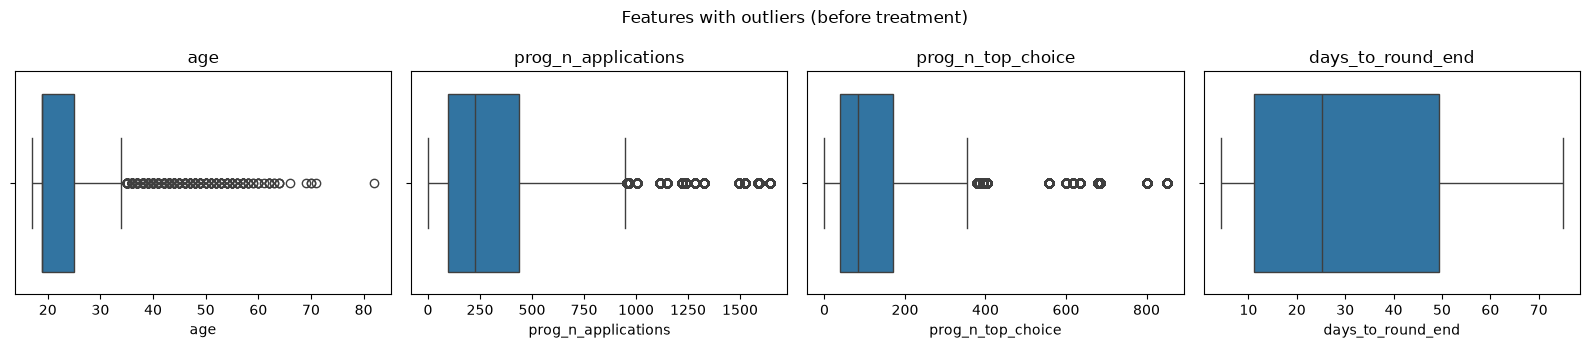

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["age", "prog_n_applications", "prog_n_top_choice", "days_to_round_end"]):
    sns.boxplot(x=data[col], ax=ax, color="tab:blue")
    ax.set_title(col)
plt.suptitle("Features with outliers (before treatment)")
plt.tight_layout()
plt.show()

* `age` – applicants born in 1942 … 2008. Older applicants are real (adult learners), so they are not removed.
  values are clipped to the 1st–99th percentile so that a few very old applicants do not dominate the scale.
* `prog_n_applications`, `prog_n_top_choice` – strongly right-skewed (a few very popular programmes),
  a `log1p` transformation is applied.
* The other "outliers" are legitimate discrete values (e.g. priority 9, applicants with earlier invitations), they are kept.

In [27]:
lo, hi = data["age"].quantile([0.01, 0.99])
data["age"] = data["age"].clip(lo, hi)
print(f"age clipped to [{lo:.0f}, {hi:.0f}]")
for col in ["prog_n_applications", "prog_n_top_choice"]:
    data[col] = np.log1p(data[col])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["age", "prog_n_applications", "prog_n_top_choice"]):
    sns.boxplot(x=data[col], ax=ax, color="tab:green")
    ax.set_title(col + (" (log1p)" if col != "age" else " (clipped)"))
plt.tight_layout()
plt.show()

age clipped to [18, 55]


NameError: name 'np' is not defined

# Machine learning algorithm (except neural network)

In [15]:
# your code

## Model with best parameters

In [16]:
# your code

# 1st neural network

In [17]:
# your code

## Model with best parameters

In [18]:
# your code

# 2nd network

In [19]:
# your code

## Model with best parameters

In [20]:
# your code

# Comparison of the best models

In [21]:
# your code

# Conclusions

..........